In [1]:

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from superfv.tools.rk_stability import compute_fv_rk_amplification, dt
from superfv.tools.polynomials import h
from superfv.tools.fv_diffusion_stability import nu
from superfv.tools.fv_advection_stability import theta

In [2]:
alpha = sp.Symbol("alpha", real=True)
dt_max = alpha * h**2 / nu
dt_max

alpha*h**2/nu

In [3]:
amplification = compute_fv_rk_amplification(7, operator="diffusion", rk="ssprk3").subs(dt, dt_max)
amplification

sqrt(3810716361*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**10/30118144000000 - 66854673*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**8*cos(theta)/13445600000 - 66854673*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**8*cos(2*theta)*cos(6*theta)/107564800000 + 1136529441*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**8*cos(2*theta)/602362880000 - 7428297*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**8*cos(3*theta)/94119200000 + 66854673*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**8*cos(8*theta)/215129600000 + 10466470473*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**8/3011814400000 + 1172889*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**6*cos(theta)**2/15006250 + 1172889*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**6*cos(theta)*cos(2*theta)*cos(6*theta)/60025000 - 19939113*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**6*cos(theta)*cos(2*theta)/336140000 + 130321*alpha**6*(1 - cos(2*theta))**2*(cos(2*theta) - 1)**6*cos(theta)*cos(3*th

In [4]:
def plot_amplification_vs_alpha(ax, p, rk, **kwargs):
    amplification = compute_fv_rk_amplification(p, operator="diffusion", rk=rk)
    amplification = amplification.subs(dt, dt_max)

    # lamdify in terms of theta and alpha
    amplification_func = sp.lambdify((theta, alpha), amplification, modules=["numpy"])

    theta_vals = np.linspace(0, 2 * np.pi, 100)
    alpha_vals = np.linspace(0.3, 0.7, 100)

    max_amps = []
    for alpha_val in alpha_vals:
        amps = amplification_func(theta_vals, alpha_val)
        max_amp = np.max(np.abs(amps))
        max_amps.append(max_amp)

    print(f"Max amplification for p={p}, rk={rk}: {np.max(max_amps)}")

    ax.plot(alpha_vals, max_amps, **kwargs)

Max amplification for p=0, rk=forward_euler: 1
Max amplification for p=1, rk=ssprk2: 2.1187315352058063
Max amplification for p=3, rk=ssprk3: 4.431865989236793
Max amplification for p=7, rk=ssprk3: 8.892967875099526
Max amplification for p=3, rk=rk4: 3.6521869605148227
Max amplification for p=7, rk=rk4: 8.953143175809725


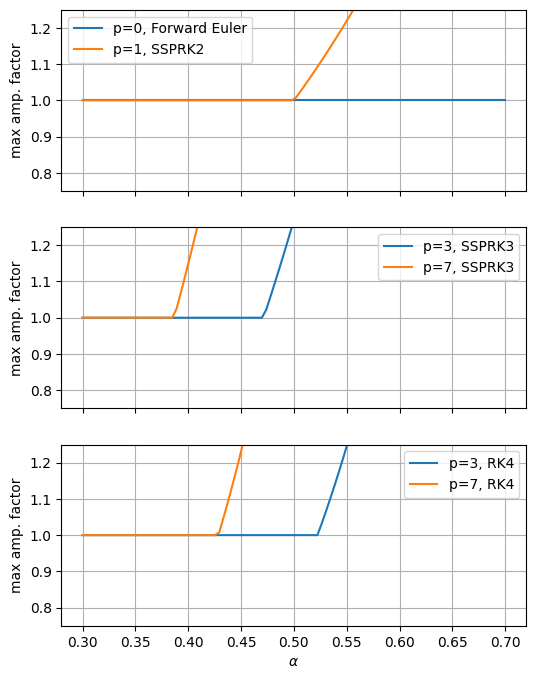

In [5]:
fig, axs = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(6, 8))
axs[2].set_xlabel(r"$\alpha$")
axs[0].set_ylim(0.75, 1.25)

plot_amplification_vs_alpha(axs[0], p=0, rk="forward_euler", label="p=0, Forward Euler")
plot_amplification_vs_alpha(axs[0], p=1, rk="ssprk2", label="p=1, SSPRK2")

plot_amplification_vs_alpha(axs[1], p=3, rk="ssprk3", label="p=3, SSPRK3")
plot_amplification_vs_alpha(axs[1], p=7, rk="ssprk3", label="p=7, SSPRK3")

plot_amplification_vs_alpha(axs[2], p=3, rk="rk4", label="p=3, RK4")
plot_amplification_vs_alpha(axs[2], p=7, rk="rk4", label="p=7, RK4")

for ax in axs.flat:
    ax.set_ylabel("max amp. factor")
    ax.grid()
    ax.legend()